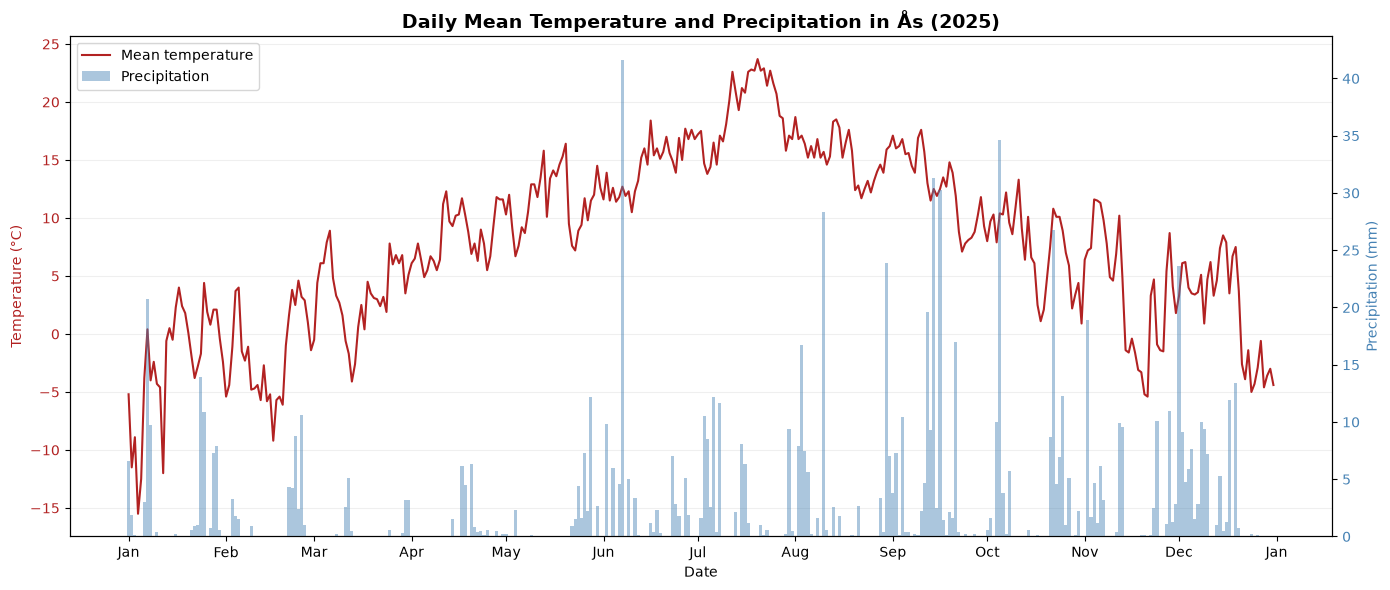

In [2]:
# INF201 - Deliverable 1
# Task 2: Temperature and Precipitation in Ås (2025)

"""

FILL IN LATER

"""

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Read the client ID form "sercrets.txt"
with open("secrets.txt", "r") as f:
    client_id = f.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"

# Request data for 2025
# End date not a part of 2025, therefore we use 2026-01-01
date_range = "2025-01-01/2026-01-01"

# Function to get data and organize it into a DataFrame
def get_weather_data(element, column_name, time_offset):

    # Set up the station, measurement type, and date range for the request
    parameters = {"sources": "SN17850", "elements": element, "referencetime": date_range}

    # Send a request to Frost using our client ID
    # timeout=30 stops waiting if the request takes longer than 30 seconds
    response = requests.get(endpoint, params=parameters, auth=(client_id, ""), timeout=30)

    rows = []

    for item in response.json()["data"]:
        for observation in item["observations"]:
            if observation["timeOffset"] == time_offset:
                rows.append({
                    "date": item["referenceTime"],
                    column_name: observation["value"]
                })

    df = pd.DataFrame(rows)
    df["date"] = pd.to_datetime(df["date"], utc=True)

    return df.sort_values("date")


# Download temperature and precipitation data
temperature = get_weather_data("mean(air_temperature P1D)", "temperature", "PT0H")

precipitation = get_weather_data("sum(precipitation_amount P1D)", "precipitation", "PT6H")

# Combine both datasets
weather_df = pd.merge(
    temperature,
    precipitation,
    on="date",
    how="inner",
    validate="one_to_one"
)

weather_df = weather_df.sort_values("date")

# Create combined plot
fig, ax1 = plt.subplots(figsize=(14, 6))

# Temperature graph
ax1.plot(
    weather_df["date"],
    weather_df["temperature"],
    color="firebrick",
    linewidth=1.5,
    label="Mean temperature"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="firebrick")
ax1.tick_params(axis="y", labelcolor="firebrick")
ax1.grid(axis="y", alpha=0.2)

# Precipitation columns
ax2 = ax1.twinx()

ax2.bar(
    weather_df["date"],
    weather_df["precipitation"],
    color="steelblue",
    alpha=0.45,
    width=1,
    label="Precipitation"
)

ax2.set_ylabel("Precipitation (mm)", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")
ax2.set_ylim(bottom=0)

# Format date axis
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Title
ax1.set_title("Daily Mean Temperature and Precipitation in Ås (2025)", fontsize=14, fontweight="bold")

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()
